<a href="https://colab.research.google.com/github/Sam-0171/Banking-customer-churn-analysis/blob/main/Bank_Churners_Github_with_explaination.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os

# What is Customer Churn ?
-  Customer churn is the number of existing customers lost, for any reason at all, over a given period of time. It provides companies with an understanding of customer satisfaction and customer loyalty, and can identify potential changes in a company’s bottom line


# How does it affect a Bank or a Credit card company ?
- Banks and credit card companies invest significant resources in acquiring new customers through promotional offers such as cashback on e-commerce transactions, complimentary airport lounge access, annual fee waivers, and zero-balance savings accounts.

- These incentives are designed to attract customers, encourage them to use banking services, and build long-term relationships. Banks may generate revenue through various activities, including payment transactions, lending, account-related services, and other financial products. However, when customers stop using their accounts or credit cards, withdraw their deposits, or shift their financial activities to competing institutions, the bank may lose potential revenue and the benefits of its customer acquisition investments.

- Customer churn can therefore lead to reduced customer lifetime value, lower transaction activity, and increased costs associated with acquiring replacement customers.


# The Business Problem
- The Bank Customer Churn dataset provides an opportunity to investigate the above problem by examining the characteristics and behavioural patterns of existing and attrited customers. Variables such as transaction amount, transaction count, months of inactivity, credit limit, and the number of products held by a customer can help us understand how customer engagement and banking relationships are associated with churn.

- The primary objective of this project is to identify the factors associated with customer attrition, develop a machine learning model to predict customers who are likely to churn, and derive actionable insights that can help banks improve customer retention and maintain long-term customer relationships.


In [2]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [3]:
# Import the dataset

df = pd.read_csv(r'/content/drive/MyDrive/BankChurners.csv')
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [4]:
df.shape

(10127, 23)

In [5]:
list(df.columns)

['CLIENTNUM',
 'Attrition_Flag',
 'Customer_Age',
 'Gender',
 'Dependent_count',
 'Education_Level',
 'Marital_Status',
 'Income_Category',
 'Card_Category',
 'Months_on_book',
 'Total_Relationship_Count',
 'Months_Inactive_12_mon',
 'Contacts_Count_12_mon',
 'Credit_Limit',
 'Total_Revolving_Bal',
 'Avg_Open_To_Buy',
 'Total_Amt_Chng_Q4_Q1',
 'Total_Trans_Amt',
 'Total_Trans_Ct',
 'Total_Ct_Chng_Q4_Q1',
 'Avg_Utilization_Ratio',
 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']

In [6]:
df.dtypes

,0
CLIENTNUM,int64
Attrition_Flag,object
Customer_Age,int64
Gender,object
Dependent_count,int64
Education_Level,object
Marital_Status,object
Income_Category,object
Card_Category,object
Months_on_book,int64


In [7]:
# Get the columns whose data type is 'object' means categorical data

df.select_dtypes(include='object').columns

Index(['Attrition_Flag', 'Gender', 'Education_Level', 'Marital_Status',
       'Income_Category', 'Card_Category'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                           

In [9]:
df.isnull().sum()

,0
CLIENTNUM,0
Attrition_Flag,0
Customer_Age,0
Gender,0
Dependent_count,0
Education_Level,0
Marital_Status,0
Income_Category,0
Card_Category,0
Months_on_book,0


In [10]:
df.describe()

,CLIENTNUM,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
count,1.012700e+04,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,7.391776e+08,46.325960,2.346203,35.928409,3.812580,2.341167,2.455317,8631.953698,1162.814061,7469.139637,0.759941,4404.086304,64.858695,0.712222,0.274894,0.159997,0.840003
std,3.690378e+07,8.016814,1.298908,7.986416,1.554408,1.010622,1.106225,9088.776650,814.987335,9090.685324,0.219207,3397.129254,23.472570,0.238086,0.275691,0.365301,0.365301
min,7.080821e+08,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000,0.000008,0.000420
25%,7.130368e+08,41.000000,1.000000,31.000000,3.000000,2.000000,2.000000,2555.000000,359.000000,1324.500000,0.631000,2155.500000,45.000000,0.582000,0.023000,0.000099,0.999660
50%,7.179264e+08,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4549.000000,1276.000000,3474.000000,0.736000,3899.000000,67.000000,0.702000,0.176000,0.000181,0.999820
75%,7.731435e+08,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,11067.500000,1784.000000,9859.000000,0.859000,4741.000000,81.000000,0.818000,0.503000,0.000337,0.999900
max,8.283431e+08,73.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.999000,0.999580,0.999990


In [11]:
df.describe(include='object')

,Attrition_Flag,Gender,Education_Level,Marital_Status,Income_Category,Card_Category
count,10127,10127,10127,10127,10127,10127
unique,2,2,7,4,6,4
top,Existing Customer,F,Graduate,Married,Less than $40K,Blue
freq,8500,5358,3128,4687,3561,9436


In [12]:
# Checking duplicate values

df.nunique()

,0
CLIENTNUM,10127
Attrition_Flag,2
Customer_Age,45
Gender,2
Dependent_count,6
Education_Level,7
Marital_Status,4
Income_Category,6
Card_Category,4
Months_on_book,44


In [13]:
# Select the Target Variable

y=df.Attrition_Flag
y.head()

,Attrition_Flag
0,Existing Customer
1,Existing Customer
2,Existing Customer
3,Existing Customer
4,Existing Customer


In [14]:
y.value_counts()

,count
Attrition_Flag,
Existing Customer,8500
Attrited Customer,1627


In [15]:
print('--- Percentage of Each Attrition_Flag Category ---\n')
print(y.value_counts(normalize=True)*100)

--- Percentage of Each Attrition_Flag Category ---

Attrition_Flag
Existing Customer    83.934038
Attrited Customer    16.065962
Name: proportion, dtype: float64


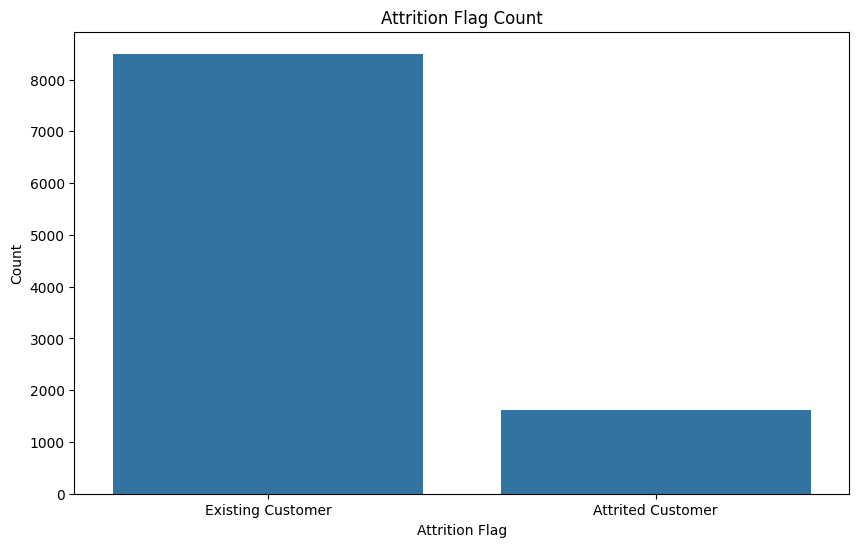

In [16]:
# Visualization

plt.figure(figsize=(10,6))
sns.countplot(x=y)
plt.title('Attrition Flag Count')
plt.xlabel('Attrition Flag')
plt.ylabel('Count')
plt.show()

In case of a bank ~ 16% attrited customer is not good sign. The ideal situation should be aorund ~ 5-6%.

So, even though the attrited customer numbers are around 2000, but still it is a big number for the bank.

In [17]:
# Drop our target variable from the main dataset

x = df.copy()
x.drop('Attrition_Flag', axis=1, inplace=True)
x.head()

,CLIENTNUM,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,45,M,3,High School,Married,$60K - $80K,Blue,39,5,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [18]:
# So x ---> Independent Variables and
#.   y ---> Dependent Variable

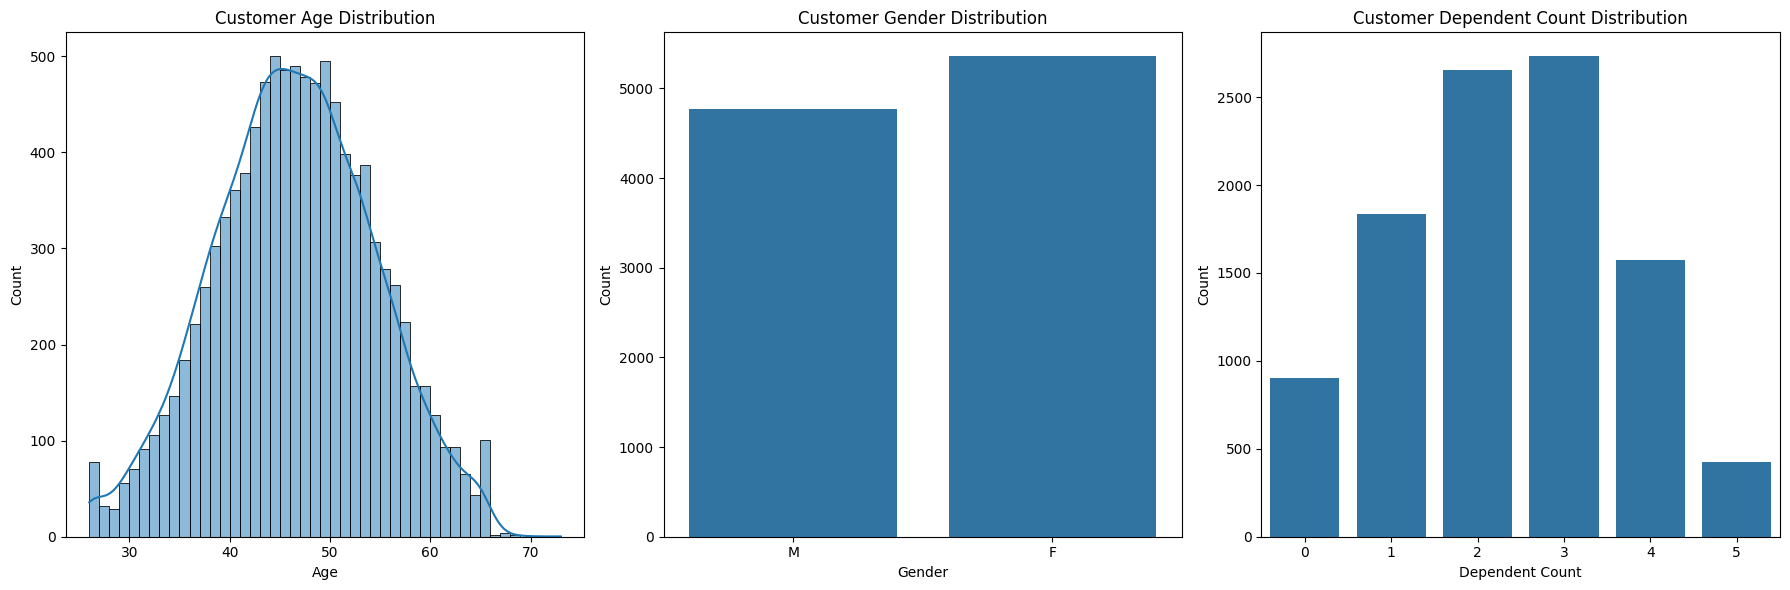

In [19]:
# Checking Customer Demographics

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Age
sns.histplot(x.Customer_Age, kde=True, ax=axes[0])
axes[0].set_title('Customer Age Distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')

# Gender
sns.countplot(x=x.Gender, ax=axes[1])
axes[1].set_title('Customer Gender Distribution')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Count')

# Dependent count
sns.countplot(x=x.Dependent_count, ax=axes[2])
axes[2].set_title('Customer Dependent Count Distribution')
axes[2].set_xlabel('Dependent Count')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()




### Conclusions from Customer Demographics

Based on the visualizations of the independent variables, we can observe the following patterns:

1. **Customer Age Distribution**:
   - The customer age distribution is approximately **normally distributed** (bell-shaped curve).
   - The majority of the customers fall within the **40 to 50 years** age range.

2. **Customer Gender Distribution**:
   - There are slightly **more female customers (F)** than male customers (M) in the dataset, though both genders are relatively well-represented.

3. **Dependent Count Distribution**:
   - Most customers have between **2 to 3 dependents**.
   - The number of dependents drops significantly for customers with 0, 1, 4, or 5 dependents, showing that mid-sized households are the primary customer base.

In [20]:
x.Income_Category.dtypes

dtype('O')

In [21]:
x.Income_Category.value_counts()

,count
Income_Category,
Less than $40K,3561
$40K - $60K,1790
$80K - $120K,1535
$60K - $80K,1402
Unknown,1112
$120K +,727


In [22]:
# Convert these into numerical values

from sklearn.preprocessing import LabelEncoder

le=LabelEncoder()
x.Income_Category=le.fit_transform(x.Income_Category)
x.Income_Category.value_counts()

,count
Income_Category,
4,3561
1,1790
3,1535
2,1402
5,1112
0,727


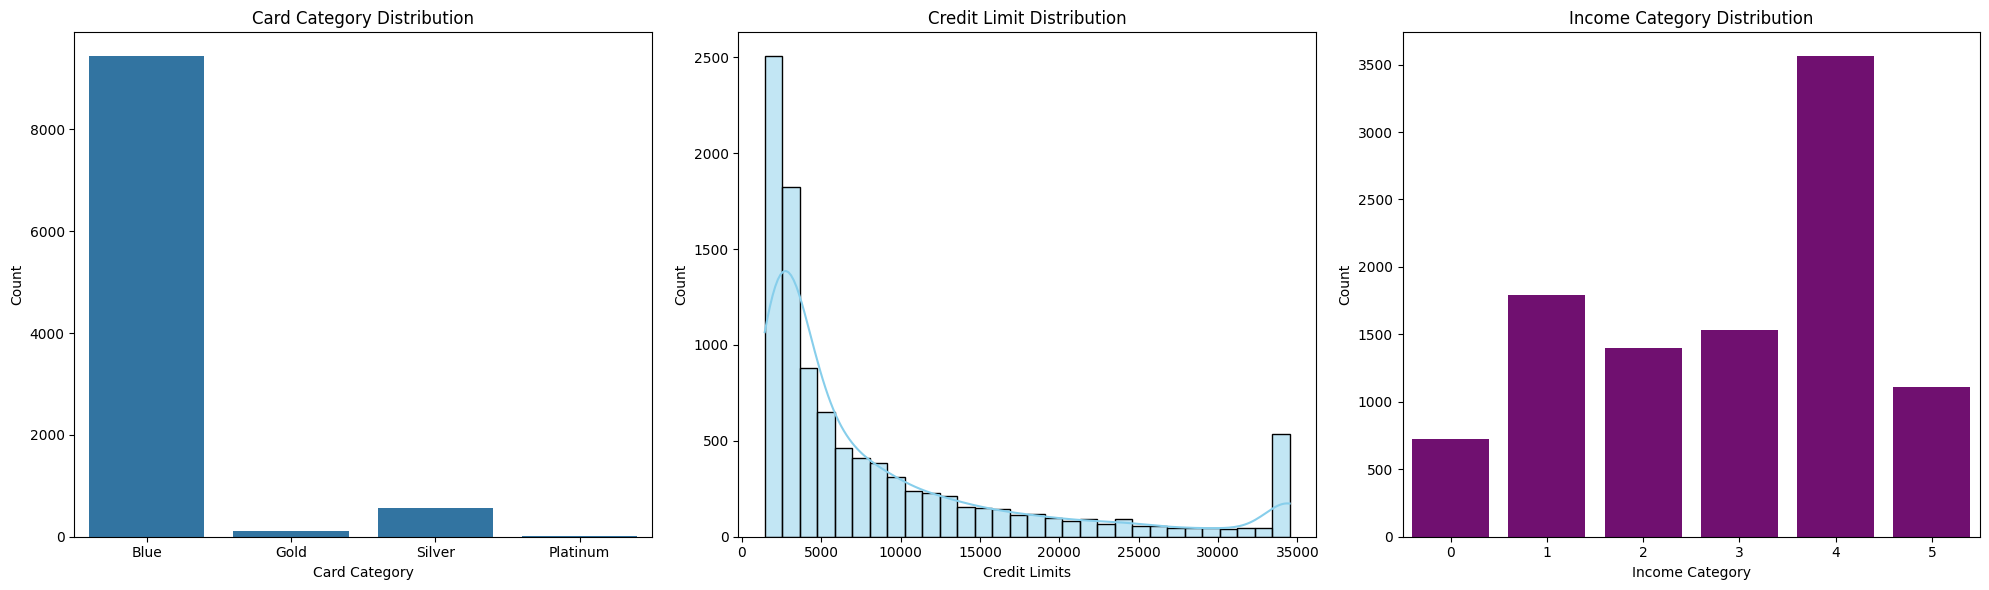

In [23]:
# Analysis of Account Information

fig, axes = plt.subplots(1, 3, figsize=(20,6))

# Credit Cards
sns.countplot(x=x.Card_Category, ax=axes[0])
axes[0].set_title('Card Category Distribution')
axes[0].set_xlabel('Card Category')
axes[0].set_ylabel('Count')


# Credit Limits
sns.histplot(x=x.Credit_Limit, ax=axes[1], bins= 30, kde=True, color='skyblue')
axes[1].set_title('Credit Limit Distribution')
axes[1].set_xlabel('Credit Limits')
axes[1].set_ylabel('Count')



# Income Category
sns.countplot(x=x.Income_Category, ax=axes[2], color='purple')
axes[2].set_title('Income Category Distribution')
axes[2].set_xlabel('Income Category')
axes[2].set_ylabel('Count')


plt.tight_layout()
plt.show()

In [24]:

print('**** Percentage of Card Category Groups ****\n')
print(x.Card_Category.value_counts(normalize=True)*100)
print('\n\n**** Percentage of Income Category Groups ****\n')
print(x.Income_Category.value_counts(normalize=True)*100)

**** Percentage of Card Category Groups ****

Card_Category
Blue        93.176656
Silver       5.480399
Gold         1.145453
Platinum     0.197492
Name: proportion, dtype: float64


**** Percentage of Income Category Groups ****

Income_Category
4    35.163425
1    17.675521
3    15.157500
2    13.844179
5    10.980547
0     7.178829
Name: proportion, dtype: float64


# Conclusions from Accounts Information

Based on the analysis and visualizations of the accounts information, we can draw the following key conclusions:

1. **Card Category Distribution**:
   - An overwhelming majority of the customers (**~93.18%**) hold a **Blue** card.
   - Premium cards like **Silver (~5.48%)**, **Gold (~1.15%)**, and **Platinum (~0.20%)** represent a very small fraction of the bank's user base.

2. **Credit Limit Distribution**:
   - The credit limit distribution is heavily **right-skewed**.
   - A large concentration of customers has lower credit limits (most under $5,000), with a sharp peak at the lower bound.

   - There is also a distinct spike of users right at the maximum limit boundary(around $34,500), which could suggest a specific limit ceiling set by the bank for premium accounts.

3. **Income Category Distribution**:
   - The largest single group of customers (**~35.16%**) belongs to the lowest income tier (**Less than $40K**, encoded as category 4).

   - This is followed by the **$40K - $60K** category (**~17.68%**, encoded as 1) and the **$80K - $120K** category (**~15.16%**, encoded as 3).
   
   - Only a small percentage (**~7.18%**, encoded as 0) earn more than **$120K+**.

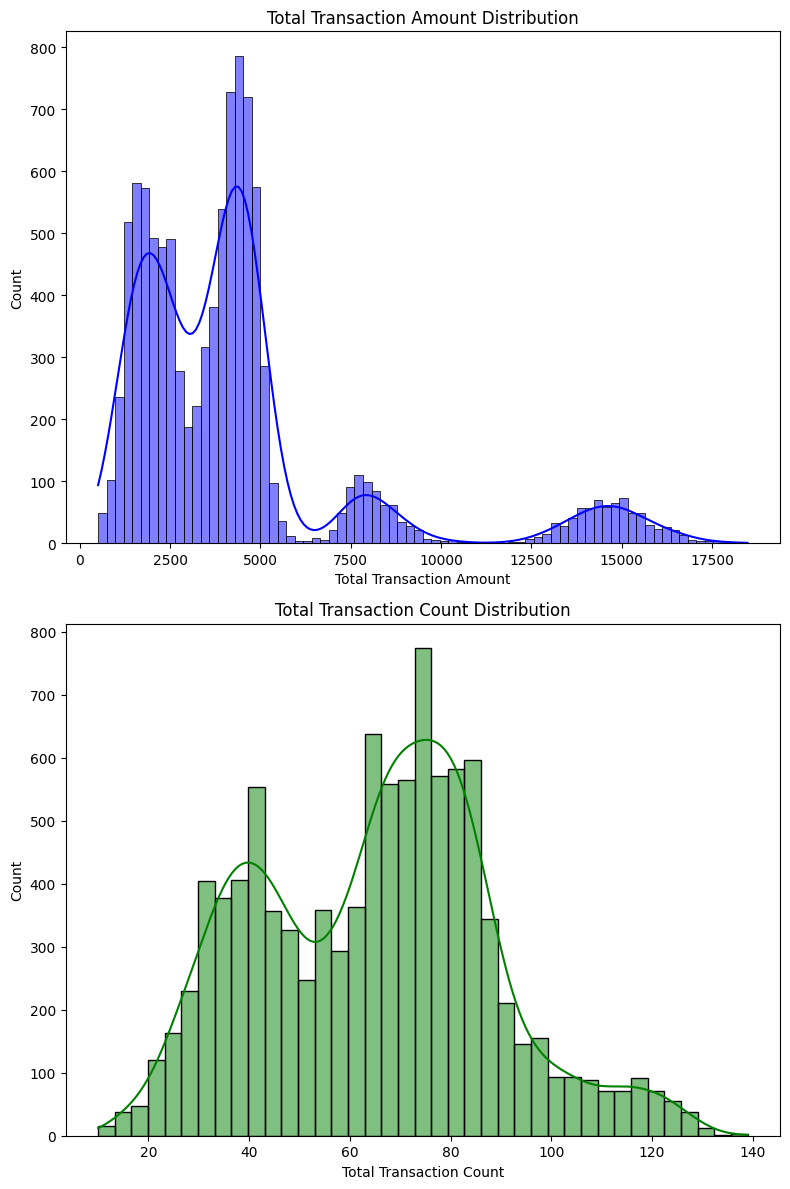

In [25]:
# Customer Activity Analysis

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(8,12))


# Total Transaction Amount
sns.histplot(x=x.Total_Trans_Amt, ax=axes[0], kde=True, color='blue', line_kws={'color':'red'})
axes[0].set_title('Total Transaction Amount Distribution')
axes[0].set_xlabel('Total Transaction Amount')
axes[0].set_ylabel('Count')


# Total Transaction Count
sns.histplot(x=x.Total_Trans_Ct, ax=axes[1], kde=True, color='green', line_kws={'color':'yellow'})
axes[1].set_title('Total Transaction Count Distribution')
axes[1].set_xlabel('Total Transaction Count')
axes[1].set_ylabel('Count')


plt.tight_layout()
plt.show()


### Conclusions from Customer Activity Analysis

Based on the visualizations of transaction behaviors and the Naive Bayes columns, we can draw the following conclusions:

1. **Total Transaction Amount Distribution**:
   - The transaction amount is strongly **multi-modal** and **right-skewed**.
   - There is a massive spike of customers making very low-value transactions (under $2,500) and around 4000-5000 dollars.

   - Additional smaller peaks appear around 7500-8500 dollars and a very small group goes up to $15,000. This indicates distinct spending  cohort among the bank's customers.

2. **Total Transaction Count Distribution**:
   - The transaction count distribution shows two prominent peaks, one around 40 transactions and another around 75–80 transactions during the period.
   - Customers who transact rarely (left side) are likely at a higher risk of churn compared to highly active transactors (right side).
   - 40 transactions is not a high number of transactions. And who have made less than 40 transactions they are in high risk of Churn.


/tmp/ipykernel_894/419930171.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Attrition_Flag', y='Total_Trans_Amt', ax=axes[0], palette='coolwarm')
/tmp/ipykernel_894/419930171.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Attrition_Flag', y='Total_Trans_Ct', ax=axes[1],palette='Set2')
/tmp/ipykernel_894/419930171.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Attrition_Flag', y='Income_Category', ax=axes[2], palette='viridis')


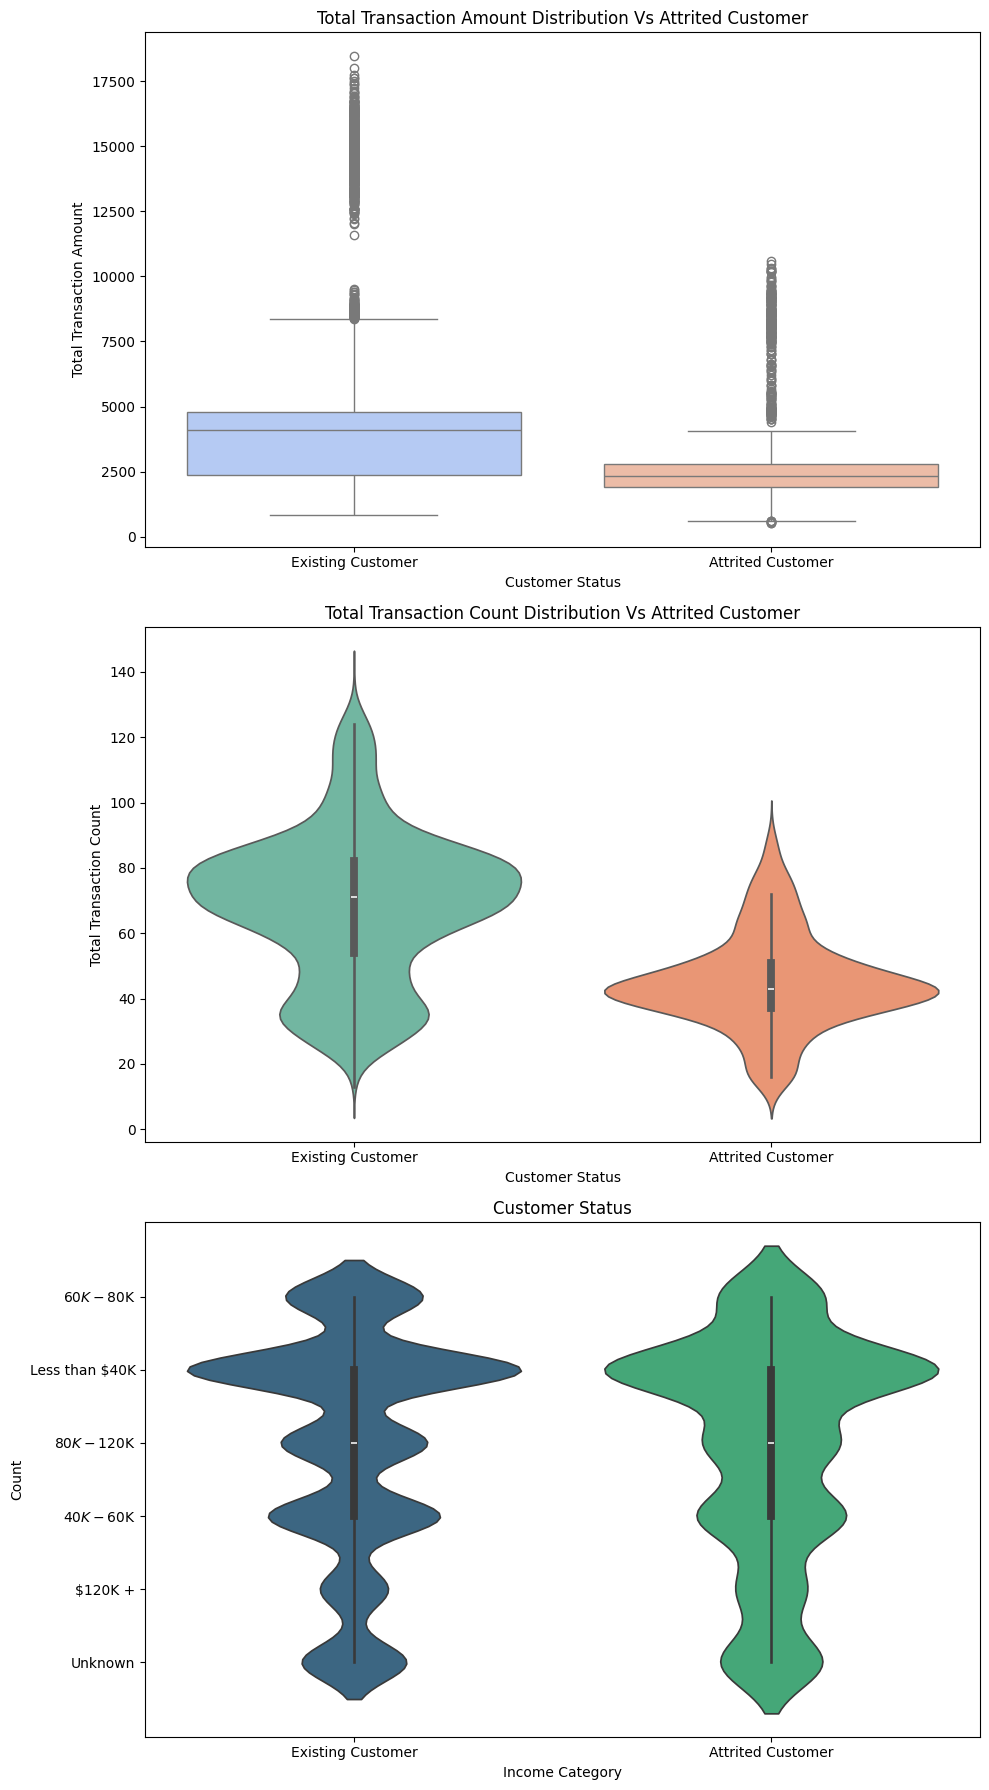

In [26]:
# Relation Between Features and Churn or Attrited customers

# Customer Activity Analysis and Churn

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10,18))


# Total Transaction Amount vs Churn
sns.boxplot(data=df, x='Attrition_Flag', y='Total_Trans_Amt', ax=axes[0], palette='coolwarm')
axes[0].set_title('Total Transaction Amount Distribution Vs Attrited Customer')
axes[0].set_xlabel('Customer Status')
axes[0].set_ylabel('Total Transaction Amount')


# Total Transaction Count vs Churn
sns.violinplot(data=df, x='Attrition_Flag', y='Total_Trans_Ct', ax=axes[1],palette='Set2')
axes[1].set_title('Total Transaction Count Distribution Vs Attrited Customer')
axes[1].set_xlabel('Customer Status')
axes[1].set_ylabel('Total Transaction Count')

# Income Category vs Churn
sns.violinplot(data=df, x='Attrition_Flag', y='Income_Category', ax=axes[2], palette='viridis')
axes[2].set_title('Customer Status')
axes[2].set_xlabel('Income Category')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()


### Conclusions: Relationship Between Customer Behavior and Churn

By comparing existing (retained) customers and attrited (churned) customers, we can draw the following key insights from the visualizations:

1. **Total Transaction Amount vs. Churn**:
   - **Existing Customers** tend to have a wider, higher distribution of transaction amounts, with a notable concentration around $3500 - $5,000 dollars.
   - **Attrited Customers** generally have lower transaction volumes, tightly clustering around lower amounts (typically under $2,500). High-value transactors rarely churn.

2. **Total Transaction Count vs. Churn**:
   - There is a very strong correlation between transaction frequency and customer retention.
   - **Attrited Customers** show a significant concentration around **30 to 50 transactions**, meaning low engagement is a primary leading indicator of churn.
   - **Existing Customers** are much more active, peaking around **70 to 90 transactions**.

3. **Income Category vs. Churn**:
   - The violin plot shows that the distribution of income levels is remarkably similar between both existing and attrited customers.
   - This implies that **income level is not a primary driver of churn**; high-income and low-income clients churn at relatively similar rates.

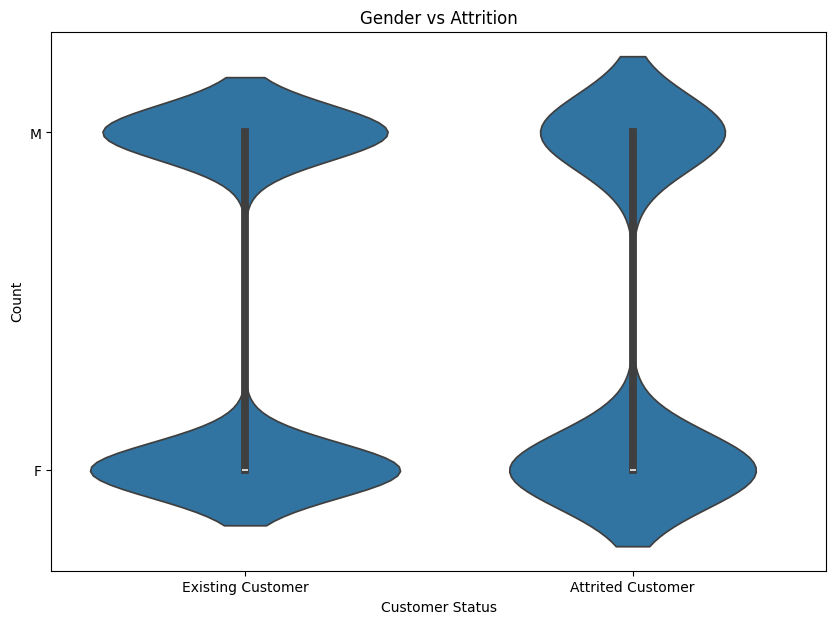

In [27]:

# Gender vs Churn

plt.figure(figsize=(10,7))
sns.violinplot(data=df, x='Attrition_Flag', y='Gender')
plt.title('Gender vs Attrition')
plt.xlabel('Customer Status')
plt.ylabel('Count')
plt.show()

### Conclusions: Gender vs. Churn Analysis

Based on the analysis of customer gender in relation to their status, we can observe the following:

1. **Proportional Attrition Rates**:
   - The violin plot shows a very similar distribution of gender across both 'Existing Customer' and 'Attrited Customer' cohorts.
   - While the raw number of females is slightly higher in the dataset, the proportion of churned females versus churned males remains highly comparable.

2. **Gender as a Predictor**:
   - Because the shape of the distributions does not change drastically between the two customer statuses, **Gender** alone is not a strong independent predictor of whether a customer will churn.

In [28]:
# Correlation Analysis

numeric_df=df.select_dtypes(include='number')
numeric_df.columns

Index(['CLIENTNUM', 'Customer_Age', 'Dependent_count', 'Months_on_book',
       'Total_Relationship_Count', 'Months_Inactive_12_mon',
       'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal',
       'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt',
       'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio',
       'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
       'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'],
      dtype='object')

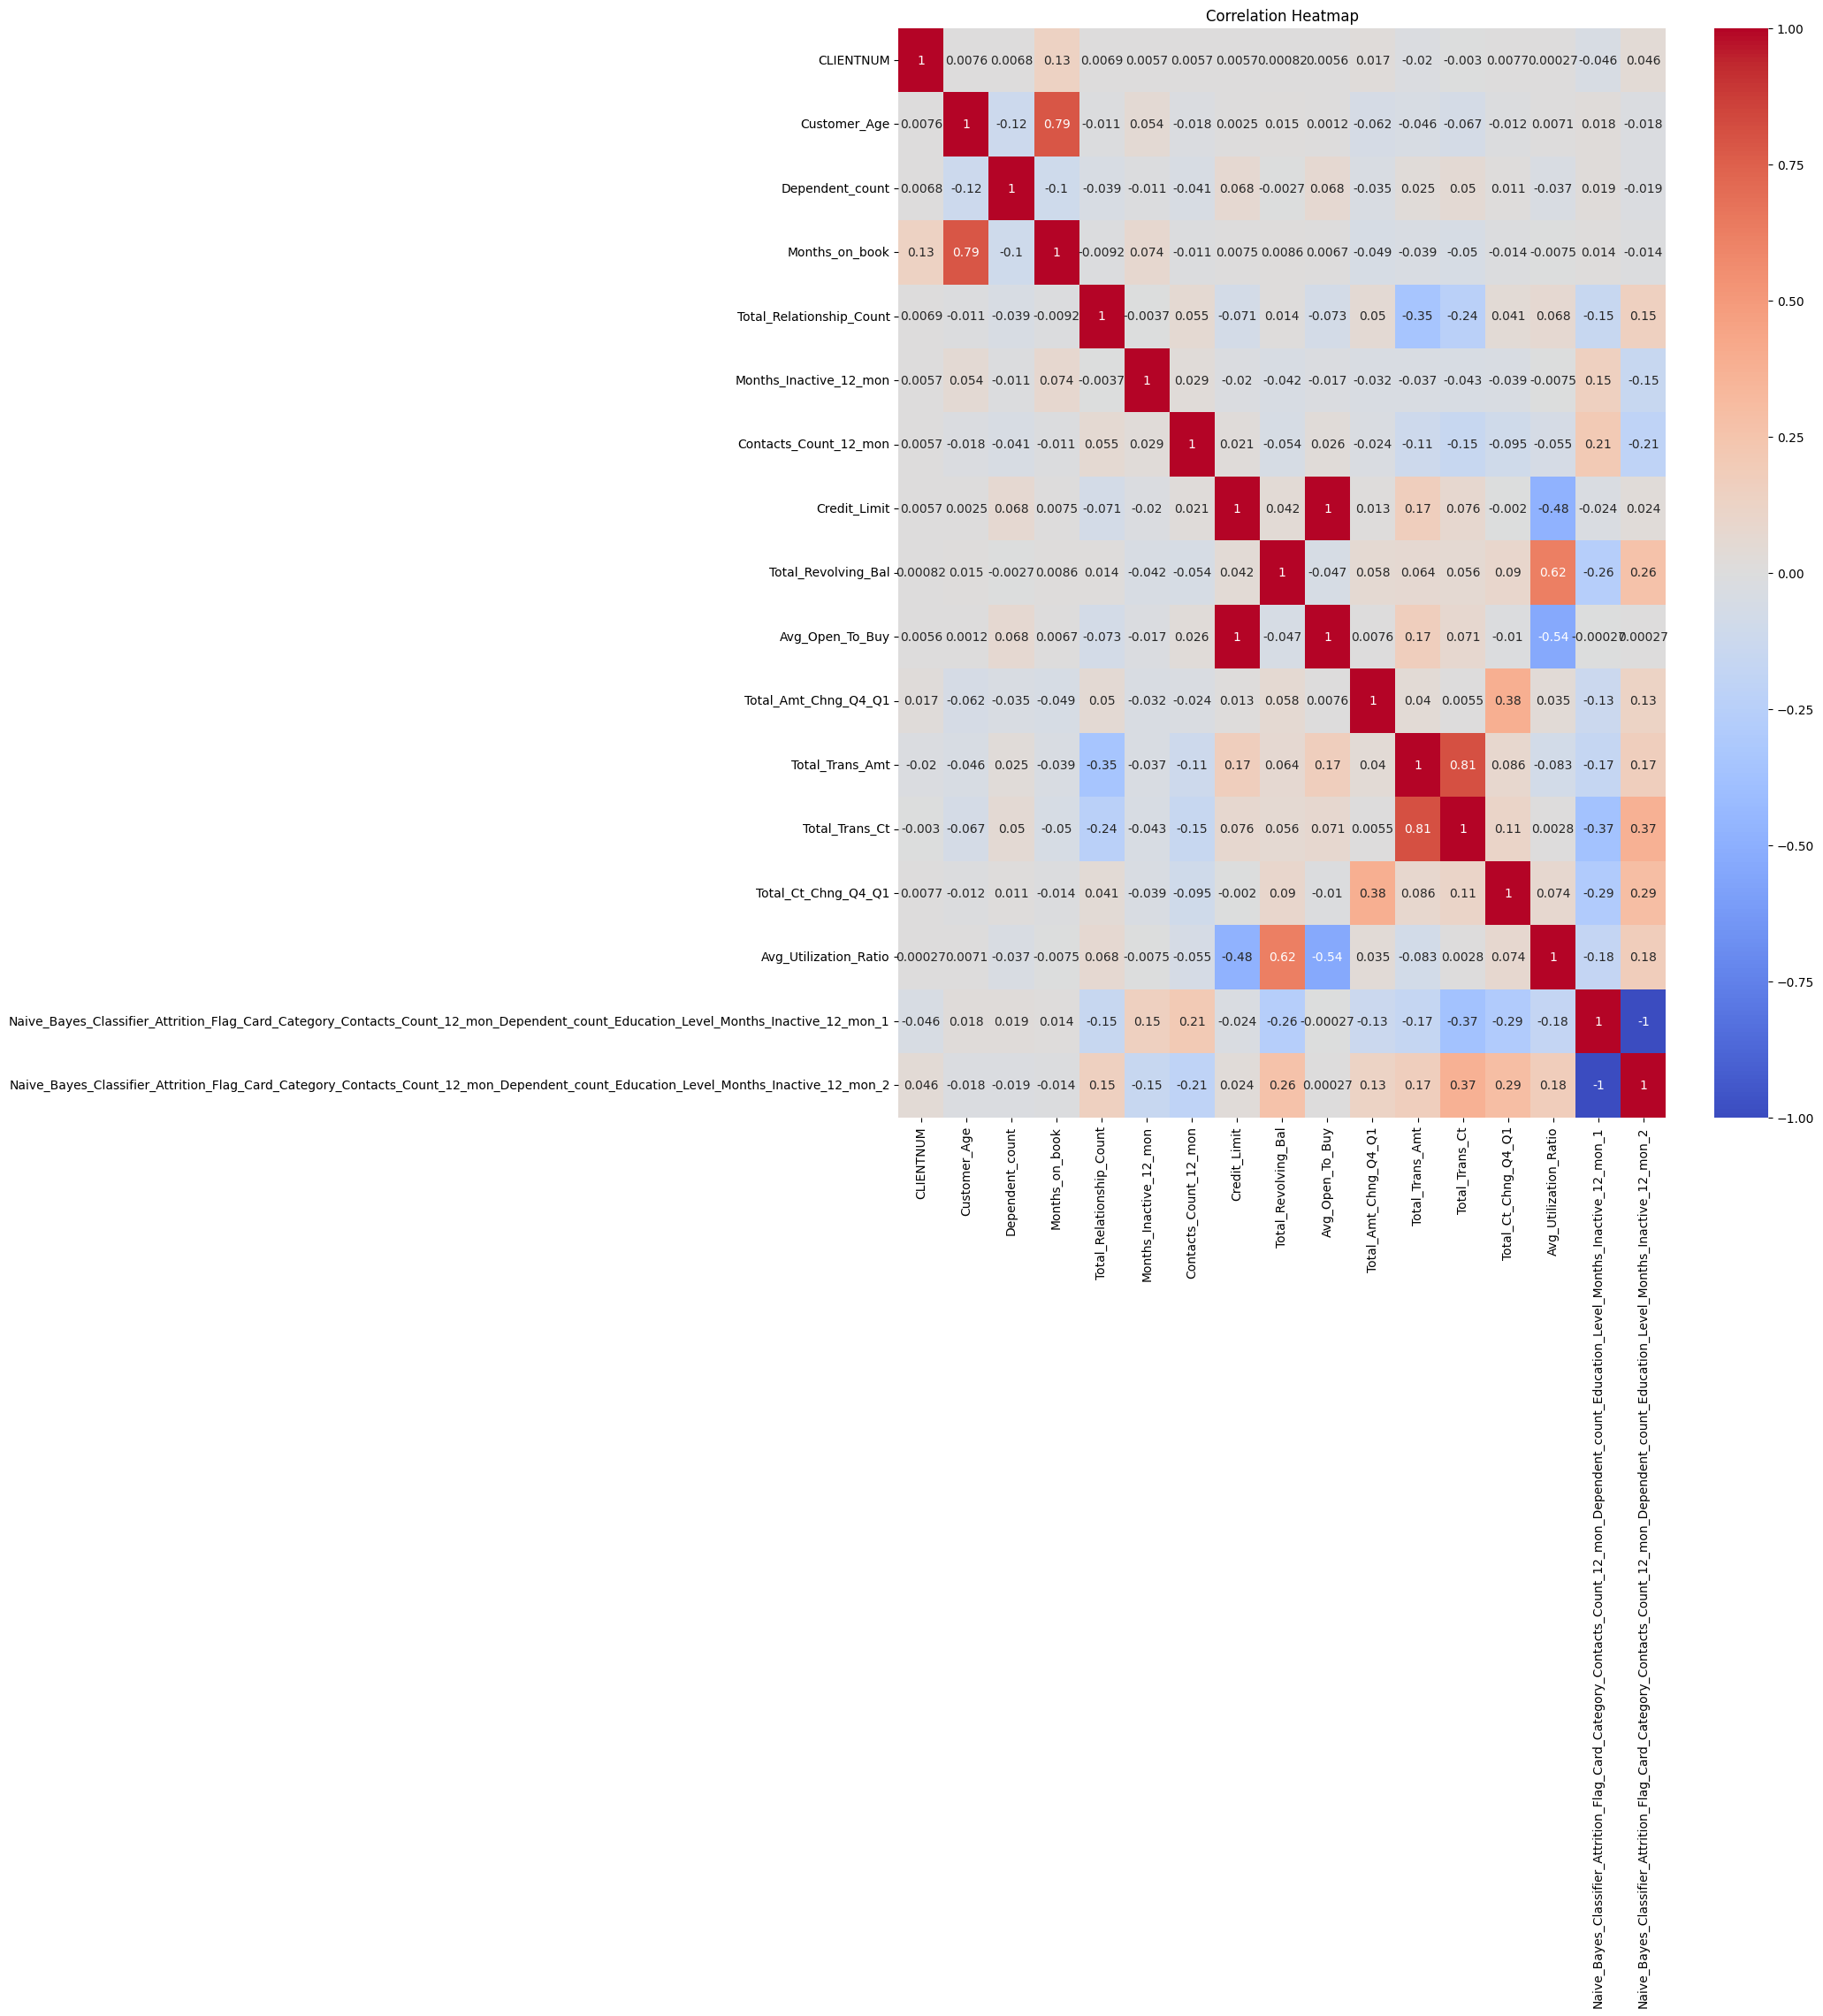

In [29]:
corr=numeric_df.corr()

plt.figure(figsize=(14,16))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

### Key Observations from the Correlation Heatmap

Looking at the correlation matrix of our numeric features, we can draw several critical insights regarding how the variables relate to each other:

1. **Strongest Positive Correlations**:
   - **`Total_Trans_Amt` and `Total_Trans_Ct` (~0.81)**: There is a very strong positive correlation here, which is highly intuitive—the more transactions a customer makes, the higher their cumulative transaction amount tends to be.
   - **`Customer_Age` and `Months_on_book` (~0.79)**: This shows a strong positive correlation, indicating that older customers naturally tend to have been with the bank for a longer period.
   - **`Credit_Limit` and `Avg_Open_To_Buy` (~0.995)**: This extremely high correlation is expected since "Open to Buy" is mathematically derived directly from the credit limit (Credit Limit minus current balance).

2. **Strongest Negative Correlations**:
   - **`Avg_Utilization_Ratio` and `Avg_Open_To_Buy` (~ -0.54)**: This moderate negative correlation indicates that customers with higher open-to-buy credit limits generally have lower utilization ratios.
   - **`Total_Revolving_Bal` and `Avg_Open_To_Buy` (~ -0.54)**: An increase in revolving balance directly reduces the open-to-buy amount, leading to a negative relationship.
   

# Data Preprocessing
### Droping unnecessary columns

In [30]:
x=x.drop(['CLIENTNUM','Gender','Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1','Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2',], axis=1)
x.head()

,Customer_Age,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,45,3,High School,Married,2,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,49,5,Graduate,Single,4,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,51,3,Graduate,Married,3,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,40,4,High School,Unknown,4,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,40,3,Uneducated,Married,2,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


In [31]:
print(x.dtypes)

for i in x.select_dtypes(include=['object']).columns:
  x[i]=le.fit_transform(x[i])

x

print('\n\n ------------------**************-----------------\n')
print(list(x.dtypes))

Customer_Age                  int64
Dependent_count               int64
Education_Level              object
Marital_Status               object
Income_Category               int64
Card_Category                object
Months_on_book                int64
Total_Relationship_Count      int64
Months_Inactive_12_mon        int64
Contacts_Count_12_mon         int64
Credit_Limit                float64
Total_Revolving_Bal           int64
Avg_Open_To_Buy             float64
Total_Amt_Chng_Q4_Q1        float64
Total_Trans_Amt               int64
Total_Trans_Ct                int64
Total_Ct_Chng_Q4_Q1         float64
Avg_Utilization_Ratio       float64
dtype: object


 ------------------**************-----------------

[dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('float64'), dtype('int64'), dtype('float64'), dtype('float64'), dtype('int64'), dtype('int64'), dtype('float64'), dty

In [32]:
x=x.drop(['Marital_Status'], axis=1)
x.columns

Index(['Customer_Age', 'Dependent_count', 'Education_Level', 'Income_Category',
       'Card_Category', 'Months_on_book', 'Total_Relationship_Count',
       'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit',
       'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1',
       'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1',
       'Avg_Utilization_Ratio'],
      dtype='object')

In [33]:
x.isnull().sum()

,0
Customer_Age,0
Dependent_count,0
Education_Level,0
Income_Category,0
Card_Category,0
Months_on_book,0
Total_Relationship_Count,0
Months_Inactive_12_mon,0
Contacts_Count_12_mon,0
Credit_Limit,0


There is no null or missing values in the whole dataset.

In [34]:
# Checking for outliers


# For the Dataset x

def boxplots(col):
  sns.boxplot(x[col])
  plt.show()

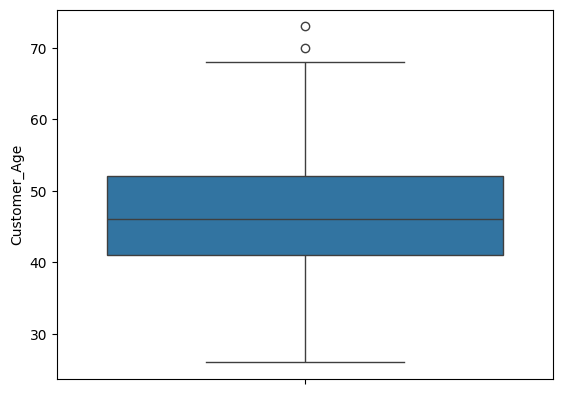

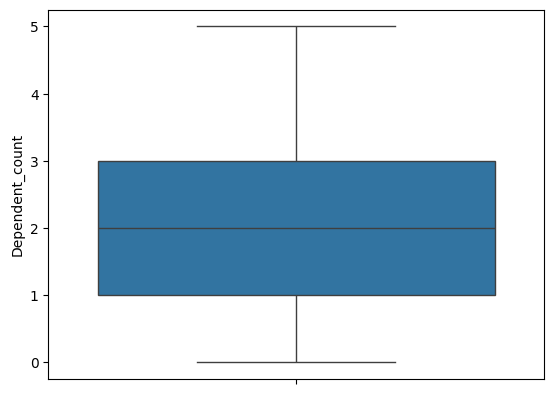

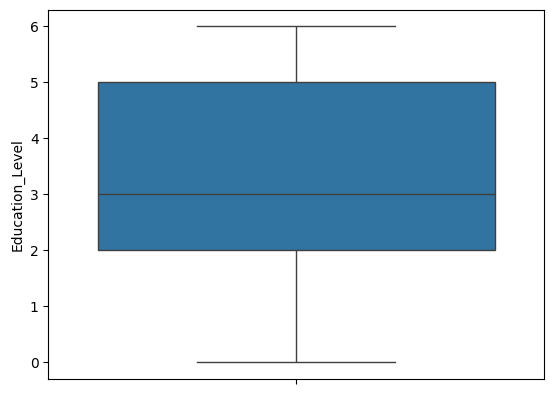

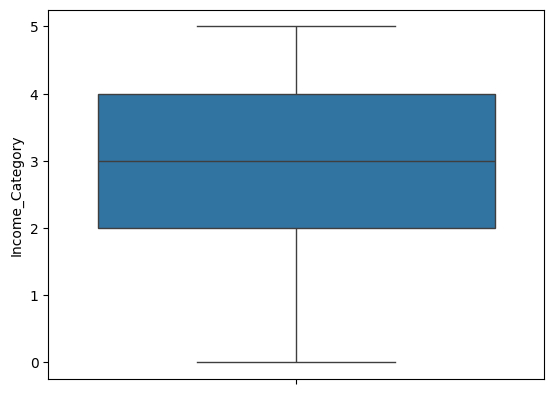

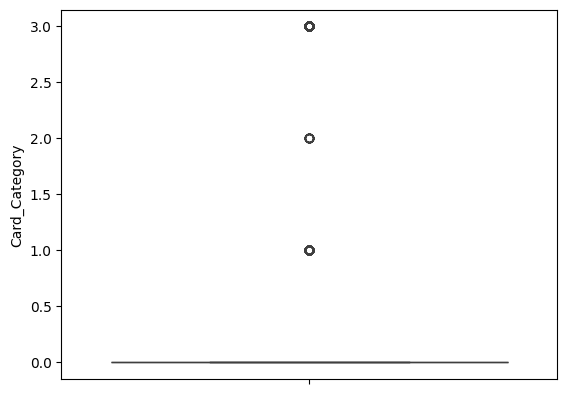

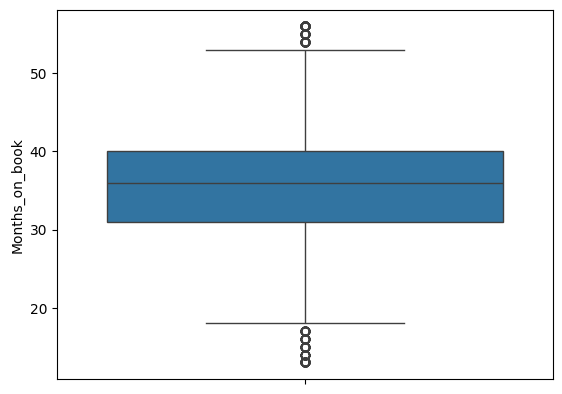

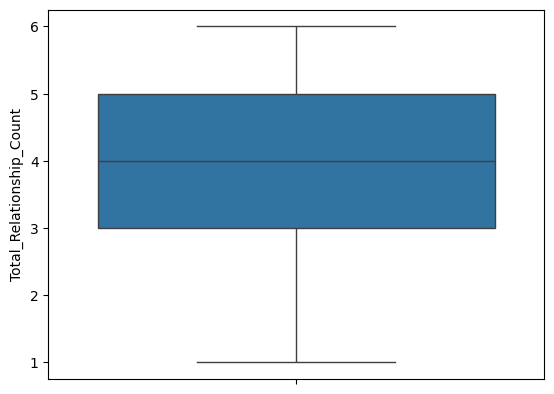

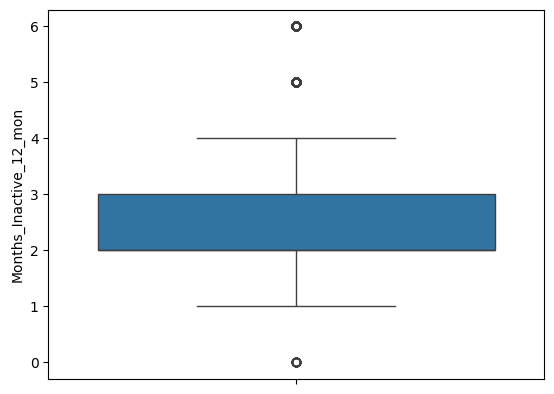

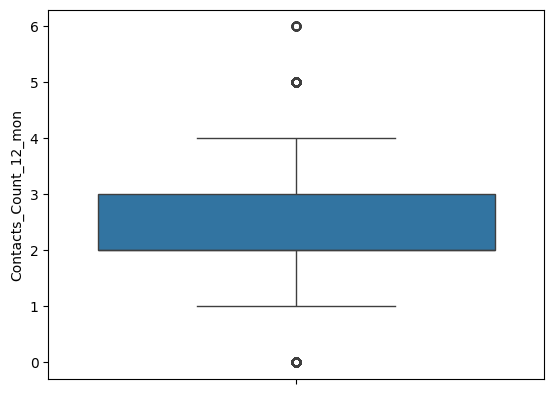

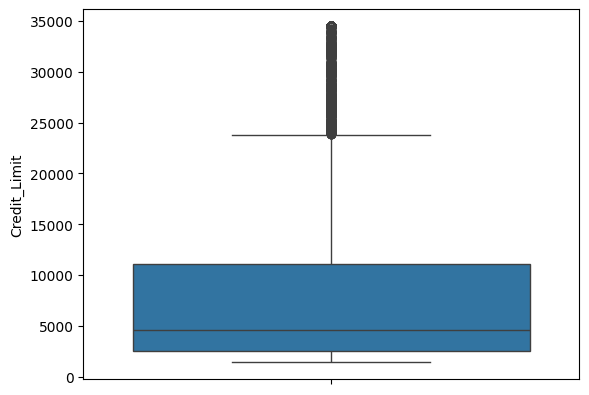

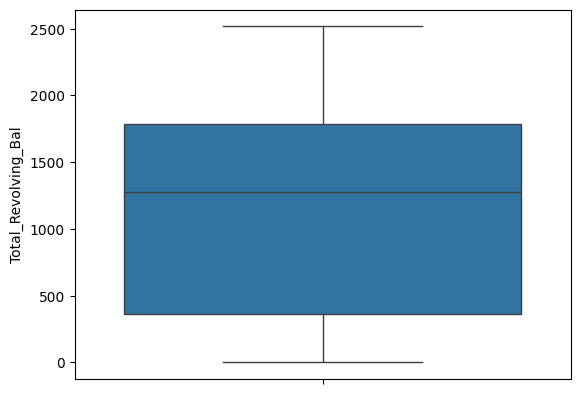

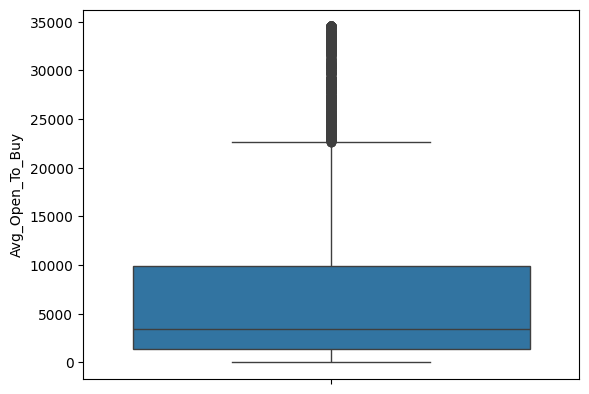

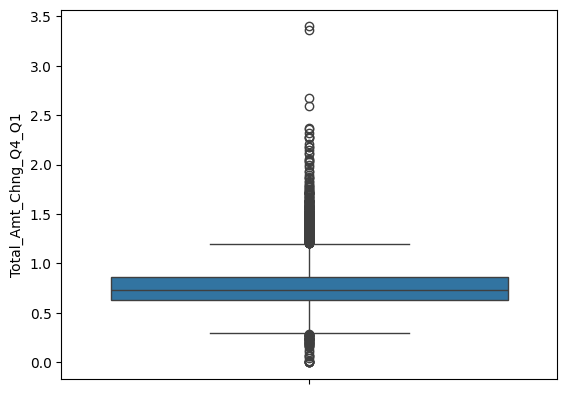

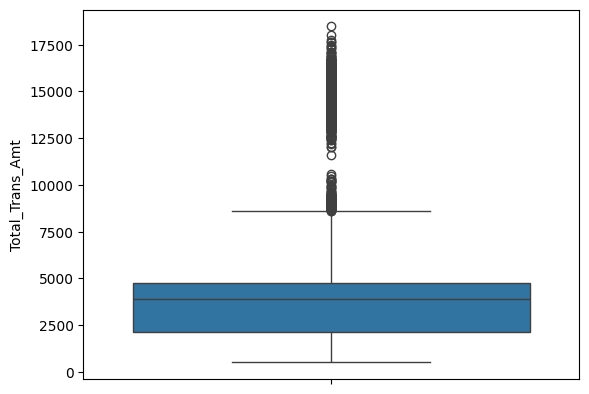

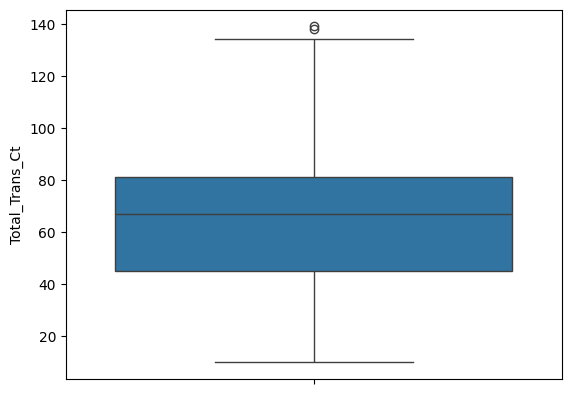

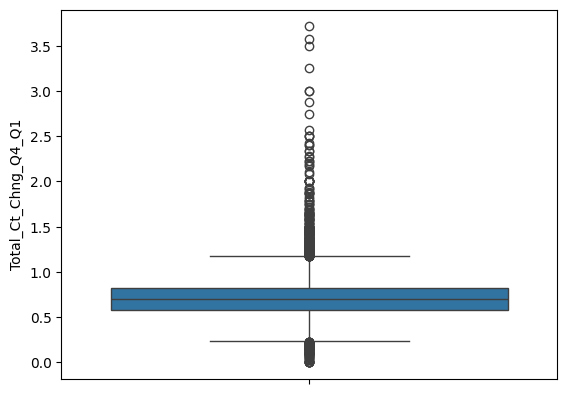

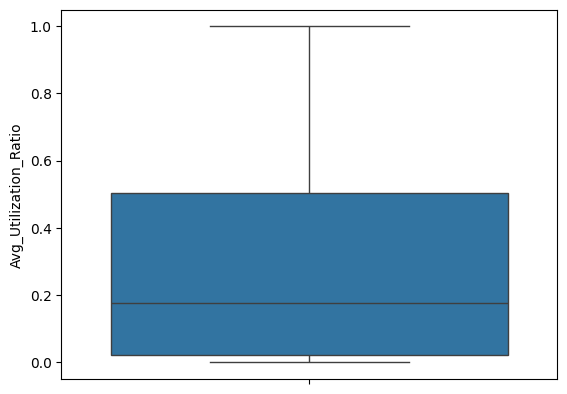

In [35]:
for i in list(x.columns):
  boxplots(i)

### Single-Line Interpretations of Feature Boxplots

1. **Customer_Age**: Shows a symmetric, near-normal distribution centered around 46 with only a couple of minor outliers on the older end.
2. **Dependent_count**: Well-balanced distribution ranging from 0 to 5, centered tightly at 2 and 3 with zero outliers.
3. **Education_Level**: Represents label-encoded categories distributed relatively evenly without any outliers.
4. **Income_Category**: Represents label-encoded salary bands showing a right-skewed layout with no extreme outliers.
5. **Card_Category**: Heavily concentrated at the lowest encoded value (representing Blue cards) with other premium card levels appearing as statistical outliers.
6. **Months_on_book**: Shows a tight, symmetric distribution centered around 36 months, with clear outlier spikes on both extreme low and high ends.
7. **Total_Relationship_Count**: Uniformly distributed from 1 to 6 products with no outliers, showing a median of 4 products held.
8. **Months_Inactive_12_mon**: Centered around 2 to 3 inactive months, with outliers representing customers inactive for 0 or more than 4 months.
9. **Contacts_Count_12_mon**: Centered around 2 to 3 contacts, with outliers representing customers with very high contact counts (5 or 6) or zero contacts.
10. **Credit_Limit**: Right-skewed distribution with a low median and many high-value outliers extending to the maximum cap of $34,511.

11. **Total_Revolving_Bal**: Moderately spread distribution with a median near 1,200 dollars, having zero outliers and a distinct group of users at 0 balance.
12. **Avg_Open_To_Buy**: Severely right-skewed distribution with many high-value outliers, closely mirroring the patterns seen in Credit Limit.
13. **Total_Amt_Chng_Q4_Q1**: Tightly clustered around 0.7 with a massive amount of outliers on both the high and low ends, indicating extreme quarterly spending variations.
14. **Total_Trans_Amt**: Right-skewed distribution centered around $4,000 with a cluster of high-spending outliers ranging up to 18,000.
15. **Total_Trans_Ct**: Centered around 67 transactions with a broad, uniform spread and zero outliers.
16. **Total_Ct_Chng_Q4_Q1**: Centered near 0.7 with many symmetric outliers on both sides representing abnormal transaction frequency drops or surges.
17. **Avg_Utilization_Ratio**: Heavily right-skewed distribution centered close to 0 with no outliers, indicating a large portion of the cohort barely utilizes their limit.

### Checking number of outliers per Column

In [36]:
Q1 = x.quantile(0.25)
Q3 = x.quantile(0.75)

IQR = Q3 - Q1

LL= Q1 - 1.5*IQR
UL= Q3 + 1.5*IQR

print('---- LOWER LIMIT ----')
print(LL)

print('\n\n---- UPPER LIMIT ----')
print(UL)

---- LOWER LIMIT ----
Customer_Age                   24.500
Dependent_count                -2.000
Education_Level                -2.500
Income_Category                -1.000
Card_Category                   0.000
Months_on_book                 17.500
Total_Relationship_Count        0.000
Months_Inactive_12_mon          0.500
Contacts_Count_12_mon           0.500
Credit_Limit               -10213.750
Total_Revolving_Bal         -1778.500
Avg_Open_To_Buy            -11477.250
Total_Amt_Chng_Q4_Q1            0.289
Total_Trans_Amt             -1722.750
Total_Trans_Ct                 -9.000
Total_Ct_Chng_Q4_Q1             0.228
Avg_Utilization_Ratio          -0.697
dtype: float64


---- UPPER LIMIT ----
Customer_Age                   68.500
Dependent_count                 6.000
Education_Level                 9.500
Income_Category                 7.000
Card_Category                   0.000
Months_on_book                 53.500
Total_Relationship_Count        8.000
Months_Inactive_12_mon     

In [37]:
# Outliers per column

((UL < x) | (x < LL)).sum()

,0
Customer_Age,2
Dependent_count,0
Education_Level,0
Income_Category,0
Card_Category,691
Months_on_book,386
Total_Relationship_Count,0
Months_Inactive_12_mon,331
Contacts_Count_12_mon,629
Credit_Limit,984


We have to now handle the outliers.
For that we will use capping method.
- Instead of filling median or average value we can replace all the outliers with NaN values
- Then apply KNNImputation method on it.
- It will take average of nearest 7 (assume) values to the NaN value, and then eventually put that average value there to replace NaN .

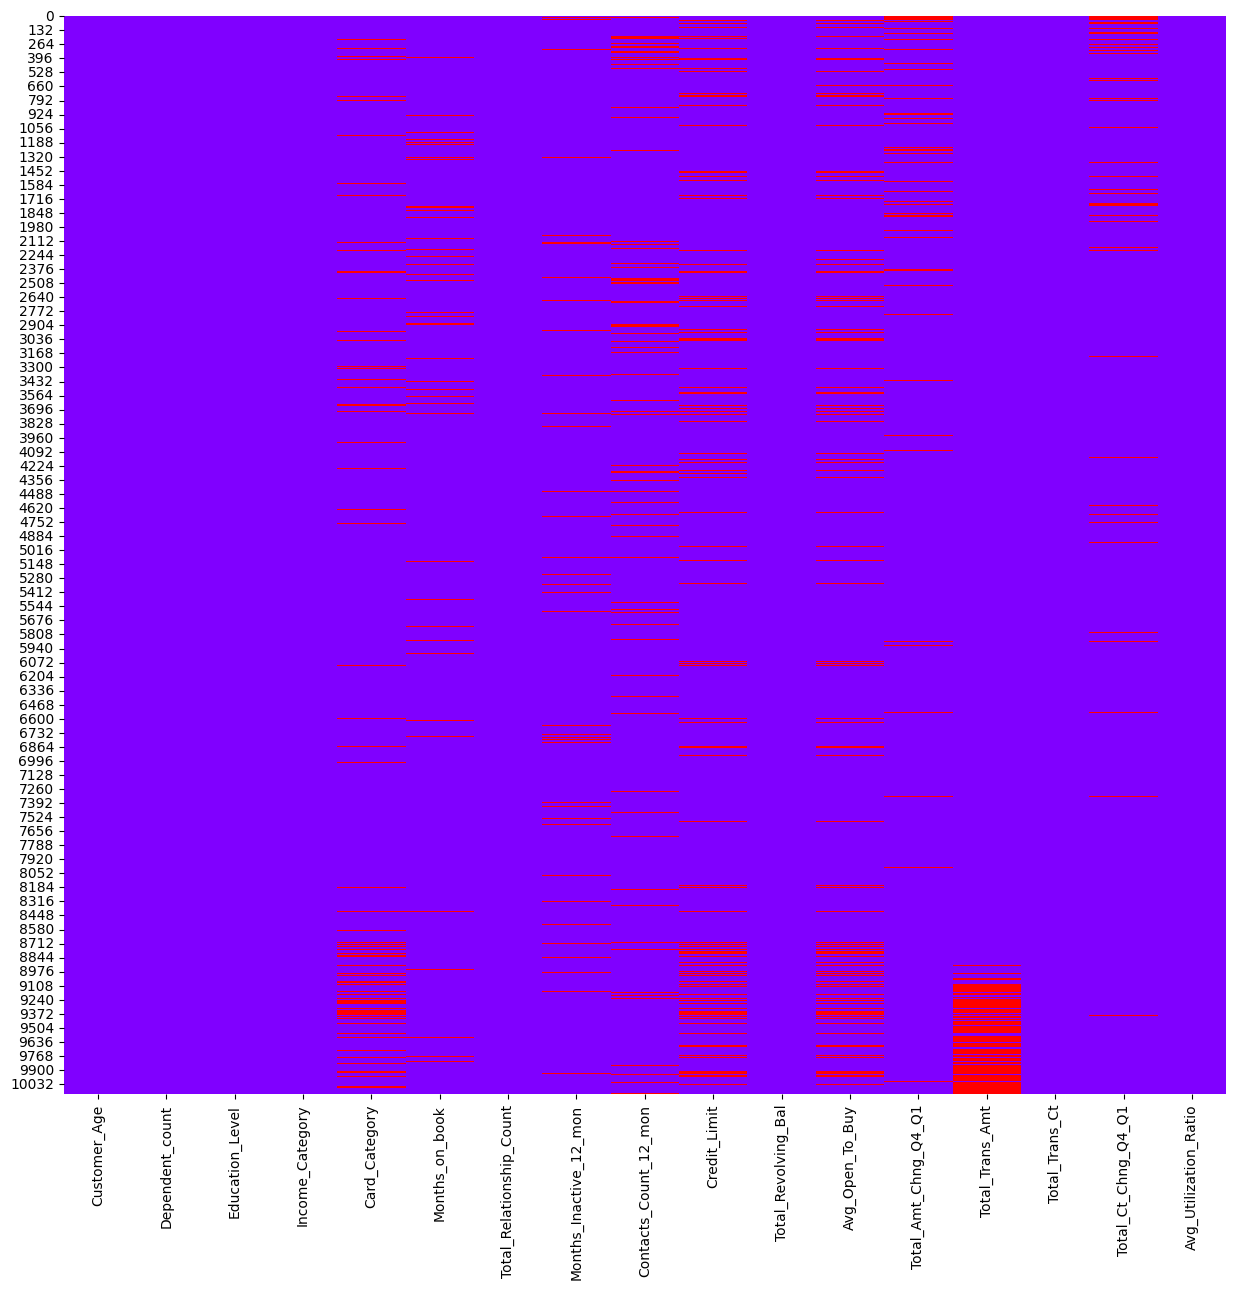

In [38]:
x[((UL < x) | (x < LL))]=np.nan

plt.figure(figsize=(15,14))
sns.heatmap(x.isnull(),cbar=False, cmap='rainbow')
plt.show()

Where there is red lines all are nan values

In [39]:
from sklearn.impute import KNNImputer
imputer = KNNImputer(n_neighbors=7)

x_impute=pd.DataFrame(imputer.fit_transform(x), columns=x.columns)
x_impute.head()



,Customer_Age,Dependent_count,Education_Level,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,45.0,3.0,3.0,2.0,0.0,39.0,5.0,1.0,3.000000,12691.0,777.0,11914.0,0.778286,1144.0,42.0,0.800429,0.061
1,49.0,5.0,2.0,4.0,0.0,44.0,6.0,1.0,2.000000,8256.0,864.0,7392.0,0.776571,1291.0,33.0,0.809429,0.105
2,51.0,3.0,2.0,3.0,0.0,36.0,4.0,1.0,3.000000,3418.0,0.0,3418.0,0.793000,1887.0,20.0,0.572857,0.000
3,40.0,4.0,3.0,4.0,0.0,34.0,3.0,4.0,1.000000,3313.0,2517.0,796.0,0.793000,1171.0,20.0,0.795286,0.760
4,40.0,3.0,5.0,2.0,0.0,21.0,5.0,1.0,3.428571,4716.0,0.0,4716.0,0.895571,816.0,28.0,0.768429,0.000


In [40]:
x_impute.describe()

,Customer_Age,Dependent_count,Education_Level,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
count,10127.000000,10127.000000,10127.000000,10127.000000,10127.0,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,46.321051,2.346203,3.096574,2.863928,0.0,35.898419,3.812580,2.253043,2.492220,6391.061197,1162.814061,5247.207035,0.738911,3713.256669,64.844235,0.695053,0.274894
std,8.009311,1.298908,1.834812,1.504700,0.0,6.964255,1.554408,0.844883,0.904306,5144.062846,814.987335,5169.854001,0.161731,1770.807498,23.449796,0.174492,0.275691
min,26.000000,0.000000,0.000000,0.000000,0.0,18.000000,1.000000,1.000000,1.000000,1438.300000,0.000000,3.000000,0.293000,510.000000,10.000000,0.231000,0.000000
25%,41.000000,1.000000,2.000000,2.000000,0.0,32.000000,3.000000,2.000000,2.000000,2552.000000,359.000000,1323.000000,0.632000,2155.500000,45.000000,0.587000,0.023000
50%,46.000000,2.000000,3.000000,3.000000,0.0,36.000000,4.000000,2.000000,2.571429,4470.000000,1276.000000,3411.000000,0.735000,3888.000000,67.000000,0.700000,0.176000
75%,52.000000,3.000000,5.000000,4.000000,0.0,40.000000,5.000000,3.000000,3.000000,8693.500000,1784.000000,7587.785714,0.842000,4700.000000,81.000000,0.805000,0.503000
max,68.000000,5.000000,6.000000,5.000000,0.0,53.000000,6.000000,4.000000,4.000000,23760.000000,2517.000000,22616.000000,1.201000,8618.000000,134.000000,1.172000,0.999000


Here, we can see that the data is unbalanced. So, we need to do featurescaling.  

In [41]:
x_impute.isnull().sum()

,0
Customer_Age,0
Dependent_count,0
Education_Level,0
Income_Category,0
Card_Category,0
Months_on_book,0
Total_Relationship_Count,0
Months_Inactive_12_mon,0
Contacts_Count_12_mon,0
Credit_Limit,0


Now all the NaN values are replaced by KNNImputers values. So , 0 null values are present in each columns.

In [42]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
x_scaled=pd.DataFrame(scaler.fit_transform(x_impute), columns=x_impute.columns)
x_scaled.head()

,Customer_Age,Dependent_count,Education_Level,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,-0.164948,0.503368,-0.052637,-0.574182,0.0,0.445379,0.763943,-1.483171,0.561541,1.224761,-0.473422,1.289615,0.243471,-1.450967,-0.974224,0.603932,-0.775882
1,0.334496,2.043199,-0.597678,0.755053,0.0,1.163367,1.407306,-1.483171,-0.544334,0.362560,-0.366667,0.414886,0.232871,-1.367950,-1.358042,0.655513,-0.616276
2,0.584218,0.503368,-0.597678,0.090436,0.0,0.014587,0.120579,-1.483171,0.561541,-0.577988,-1.426858,-0.353839,0.334456,-1.031364,-1.912445,-0.700328,-0.997155
3,-0.789252,1.273283,-0.052637,0.755053,0.0,-0.272608,-0.522785,2.067793,-1.650209,-0.598401,1.661686,-0.861035,0.334456,-1.435719,-1.912445,0.574458,1.759686
4,-0.789252,0.503368,1.037447,-0.574182,0.0,-2.139375,0.763943,-1.483171,1.035488,-0.325646,-1.426858,-0.102756,0.968697,-1.636203,-1.571274,0.420533,-0.997155


## Spliting Data into Train and Test dataset

In [43]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x_scaled, y, test_size=0.2, random_state=42, stratify=y)

In [44]:
from sklearn.ensemble import RandomForestClassifier

rf=RandomForestClassifier(random_state=42)
rf.fit(x_train, y_train)
rf.feature_importances_

array([0.04069481, 0.01575748, 0.01363411, 0.01309326, 0.        ,
       0.02596971, 0.07828027, 0.0271537 , 0.01677088, 0.03955186,
       0.11009736, 0.03642987, 0.05550258, 0.19148724, 0.16528382,
       0.10192756, 0.0683655 ])

In [45]:
pred_train_rf=rf.predict(x_train)
pred_test_rf=rf.predict(x_test)

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report, accuracy_score
from sklearn.metrics import roc_auc_score, roc_curve, auc, precision_score, recall_score, precision_recall_curve
from sklearn.model_selection import cross_val_score


In [47]:
print('*****--***** Confusion Matrix *****--*****\n\n',
confusion_matrix(y_train, pred_train_rf))

*****--***** Confusion Matrix *****--*****

 [[1301    1]
 [   0 6799]]


### Conclusions from the Training Confusion Matrix

Based on the confusion matrix output for the training set:
```
[[1301    1]
 [   0 6799]]
```
We can draw the following conclusions:

1. **Exceptional Fit on Training Data**: Out of $8,101$ training samples, the Random Forest model correctly classifies almost all of them. It successfully predicts **$1,301$ Attrited Customers** (True Positives/Negatives depending on class mapping) and **$6,799$ Existing Customers**.
2. **Extremely Low Error**: There is only **$1$ misclassified instance** (where an Attrited Customer was predicted as an Existing Customer), and **$0$** instances of the other class misclassified on the training set.


It may be a case of Overfitting, we have check for the test dataset also

In [48]:
print('*****--***** Confusion Matrix (Test set) *****--*****\n\n',
confusion_matrix(y_test, pred_test_rf))

*****--***** Confusion Matrix (Test set) *****--*****

 [[ 252   73]
 [  31 1670]]


In [49]:
print('*****--***** Classification Report (Train) *****--*****\n\n',
classification_report(y_train, pred_train_rf),'\n\n\n')
print('*-*-'*25,'\n\n\n')


print('*****--***** Classification Report (Test) *****--*****\n\n',
classification_report(y_test, pred_test_rf))


*****--***** Classification Report (Train) *****--*****

                    precision    recall  f1-score   support

Attrited Customer       1.00      1.00      1.00      1302
Existing Customer       1.00      1.00      1.00      6799

         accuracy                           1.00      8101
        macro avg       1.00      1.00      1.00      8101
     weighted avg       1.00      1.00      1.00      8101
 



*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*- 



*****--***** Classification Report (Test) *****--*****

                    precision    recall  f1-score   support

Attrited Customer       0.89      0.78      0.83       325
Existing Customer       0.96      0.98      0.97      1701

         accuracy                           0.95      2026
        macro avg       0.92      0.88      0.90      2026
     weighted avg       0.95      0.95      0.95      2026




# ====== MODEL PERFORMANCE INTERPRETATION ======
1. Overall Accuracy:
   - The model achieves an outstanding 95% overall accuracy on the test set, showing that it generalizes very well to unseen data despite the nearly 100% (perfect) performance on the training set.
2. Performance on Retained/Existing Customers (Majority Class):
   - Precision is 96% and Recall is 98% (F1-score of 97%). The model is exceptionally reliable at identifying customers who will stay with the bank, with minimal false alarms.
3. Performance on Churned/Attrited Customers (Minority/Target Class):
   - Precision is 89%: When the model flags a customer as likely to churn, it is correct 89% of the time.
   - Recall is 78%: The model successfully catches 78% of the actual churning customers (leaving 22% undetected).
   - F1-Score is 83%: A strong balanced metric for the class of interest in an imbalanced scenario.
#
## Summary: The model is robust. But there is scope for improvization.

## Recursive Feature Technique
- RFE : Recursive Feature Elimination : It trains random forest model again and again, ranks features by their importance and drops the least important features.

In [51]:
from sklearn.feature_selection import RFE
rf_1= RandomForestClassifier()

feature_1=RFE(rf_1, n_features_to_select=12,step=1)

In [52]:
feature_1=feature_1.fit(x_train, y_train)


pred_train_rf_1=feature_1.predict(x_train)
pred_test_rf_1=feature_1.predict(x_test)

In [53]:
print('*****--***** Confusion Matrix (Test set) *****--*****\n\n',
confusion_matrix(y_test, pred_test_rf_1))

*****--***** Confusion Matrix (Test set) *****--*****

 [[ 254   71]
 [  32 1669]]


In [54]:
print('********* Classification Report(Train) ***********\n\n')
print(classification_report(y_train, pred_train_rf_1))

print('\n\n\n********* Accuracy Score (Test) ***********\n\n')
print(accuracy_score(y_test, pred_test_rf_1))


print('\n\n\n********* Classification Report (Test) ***********\n\n')
print(classification_report(y_test, pred_test_rf_1))

********* Classification Report(Train) ***********


                   precision    recall  f1-score   support

Attrited Customer       1.00      1.00      1.00      1302
Existing Customer       1.00      1.00      1.00      6799

         accuracy                           1.00      8101
        macro avg       1.00      1.00      1.00      8101
     weighted avg       1.00      1.00      1.00      8101




********* Accuracy Score (Test) ***********


0.9491609081934848



********* Classification Report (Test) ***********


                   precision    recall  f1-score   support

Attrited Customer       0.89      0.78      0.83       325
Existing Customer       0.96      0.98      0.97      1701

         accuracy                           0.95      2026
        macro avg       0.92      0.88      0.90      2026
     weighted avg       0.95      0.95      0.95      2026



In [62]:

print('\n\n\n********* Accuracy Score (Train) ***********\n\n')
print(accuracy_score(y_train, pred_train_rf_1))




********* Accuracy Score (Train) ***********


1.0


*Here the result for Train is 1, i.e overfitting. So, we can opt for cross validation method*

In [56]:
# Cross Validation Method

from sklearn.model_selection  import cross_val_score
rf_cv=cross_val_score(feature_1, x_train, y_train, cv=10)

In [57]:
print(rf_cv)

[0.96177559 0.95185185 0.95185185 0.95432099 0.95308642 0.95308642
 0.95185185 0.95925926 0.95802469 0.94197531]


In [58]:
print(rf_cv.mean())

0.9537084227671979


In [60]:
from sklearn.ensemble import GradientBoostingClassifier

gb= GradientBoostingClassifier(random_state=42)
gb.fit(x_train, y_train)

pred_train_gb= gb.predict(x_train)
pred_test_gb= gb.predict(x_test)

print('********* Gradient Boosting Accuracy Score ***********\n')
print(f'Train Accuracy: {accuracy_score(y_train, pred_train_gb):.4f}')

print('\n\n********* Gradient Boosting Accuracy Score (Test) ***********\n')
print(f'Test Accuracy: {accuracy_score(y_test, pred_test_gb):.4f}')

********* Gradient Boosting Accuracy Score ***********

Train Accuracy: 0.9649


********* Gradient Boosting Accuracy Score (Test) ***********

Test Accuracy: 0.9482


In [61]:

print('\n\n********* Classification Report (Test Set) ***********')
print(classification_report(y_test, pred_test_gb))



********* Classification Report (Test Set) ***********
                   precision    recall  f1-score   support

Attrited Customer       0.89      0.77      0.83       325
Existing Customer       0.96      0.98      0.97      1701

         accuracy                           0.95      2026
        macro avg       0.92      0.88      0.90      2026
     weighted avg       0.95      0.95      0.95      2026



*Among the two models, **Gradient Boosting demonstrates more realistic and consistent performance** compared to Random Forest. It achieves an accuracy of approximately **96.49% on the training dataset and 94.82% on the test dataset**, indicating a relatively small difference between training and testing performance.*

*In contrast, the Random Forest model achieves 100% accuracy on the training dataset but its accuracy drops to 94.91% on the test dataset. This significant difference suggests that the model may be overfitting the training data and may not generalize as effectively to unseen data.*

*Therefore, although both models exhibit comparable test accuracy, **Gradient Boosting demonstrates better generalization and a lower tendency to overfit**, making it a more reliable choice based on the observed results.*